In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
import src.io_utils as io
import src.viz as viz
from src.Healthanalyzer import HealthAnalyzer

np.random.seed(42)
analyzer = HealthAnalyzer("data/health_study_dataset.csv")


plt.rcParams["figure.figsize"] = (8,5)

Data har laddats in utan problem från: data/health_study_dataset.csv (Totalt 800 rader)


In [2]:
io.check_file(analyzer.df)


Data info:

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB
Dubletter:  0


In [3]:
#counting mean, median, min, max for the columns age, weight, height, systolic_pb and cholesterol
stats_df = analyzer.desc_stats()
print(stats_df)


             age   weight     height  systolic_bp  cholesterol
mean    49.42625   73.413  171.84925   149.178625      4.92915
median  50.00000   73.200  171.35000   149.400000      4.97000
min     18.00000   33.700  144.40000   106.800000      2.50000
max     90.00000  114.400  200.40000   185.900000      7.88000


# Graphs

# Histogram

Visar fördelningen är personernas blodtryck

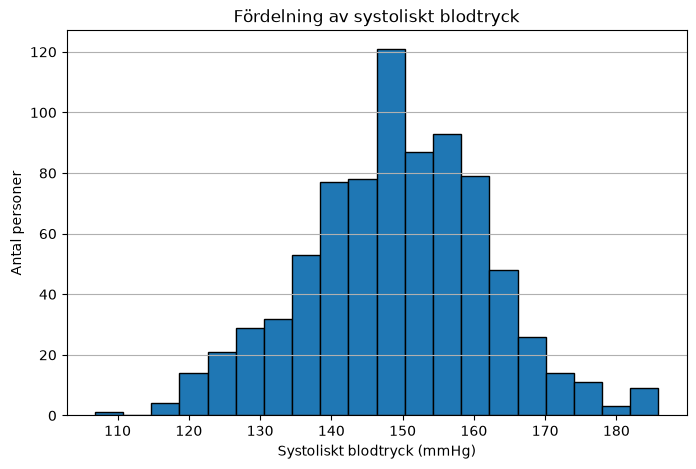

In [4]:
fig, ax = plt.subplots()
viz.hist(
    ax= ax, 
    x= analyzer.df["systolic_bp"], 
    bins= 20, 
    title= "Fördelning av systoliskt blodtryck", 
    xlabel= "Systoliskt blodtryck (mmHg)", 
    ylabel= "Antal personer"
)
plt.show()

# Boxplot

Visar vikter på personernas vikter kategoriserade på kön

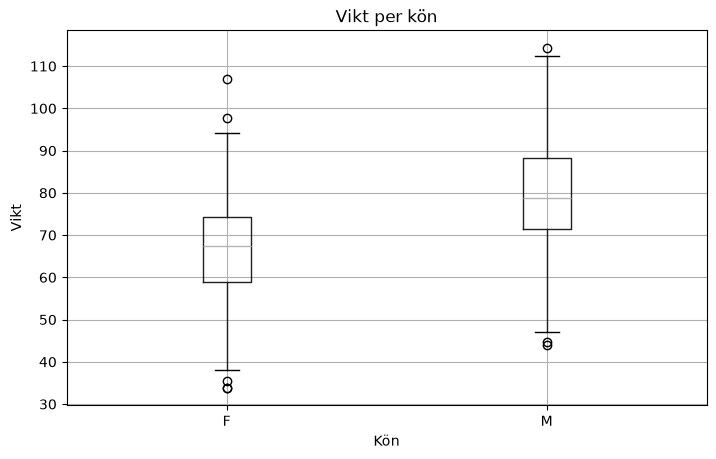

In [5]:
fig, ax = plt.subplots()
viz.box(
    df=analyzer.df, 
    ax=ax, 
    column="weight", 
    by="sex", 
    title="Vikt per kön", 
    xlabel="Kön", 
    ylabel="Vikt"
)
plt.show()

# Stapeldiagram

Visar antalet personer som är rökare eller icke-rökare

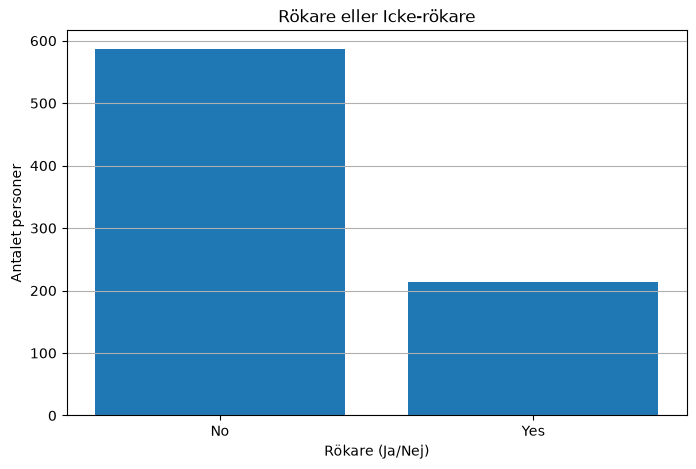

In [6]:
smoker_counts = analyzer.df["smoker"].value_counts()

fig, ax = plt.subplots()
viz.bar(
    ax= ax,
    x= smoker_counts.index, 
    y= smoker_counts.values, 
    title= "Rökare eller Icke-rökare", 
    xlabel= "Rökare (Ja/Nej)", 
    ylabel= "Antalet personer"
)
plt.show()

# Simulation

In [7]:
#Simulation, count share of who has disease

share_disease = np.mean(analyzer.df["disease"])

share_sample = analyzer.sim_disease(1000, "disease")

print(f"""
Simuleringens andel som har sjukdomen: {share_sample * 100:.2f}%
Verkliga andelen som har sjukdomen: {share_disease * 100:.2f}%
Differensen mellan simuleringen och den verkliga andelen som har sjukdomen: {(share_sample - share_disease)*100:.2f}%
""")



Simuleringens andel som har sjukdomen: 6.30%
Verkliga andelen som har sjukdomen: 5.88%
Differensen mellan simuleringen och den verkliga andelen som har sjukdomen: 0.43%



# Konfidensintervall

## Bootstrap

In [8]:
#CI for mean of systolic_bp bootstrap

boot_low, boot_high = analyzer.ci_boot(1000, "systolic_bp")

print(f"Bootstrap metoden ger ett 95%igt konfidensintervall mellan {boot_low:.3f} och {boot_high:.3f} ")

Bootstrap metoden ger ett 95%igt konfidensintervall mellan 148.330 och 150.069 


## Normalapproximation


In [9]:
normal_low, normal_high = analyzer.ci_norm("systolic_bp")

print(f"Normalapproximationsmetoden ger ett 95%igt konfidensintervall mellan {normal_low:.3f} och {normal_high:.3f} ")


Normalapproximationsmetoden ger ett 95%igt konfidensintervall mellan 148.292 och 150.065 


## Jämförelse resultat mellan konfidensintervallen

De är nästan samma vilket stärker tillit till skattningen. Bootstrap: (148.330 och 150.069 ) Normal approximationen: (148.292 och 150.065)

Vi kan anta att med 95% säkerhet ligger det sanna medelvärdet av blodtrycket i spannet som våra konfidensintervall har plockat fram.

## Hypotesprövning

- Utgångsläge (H0 - Nollhypotesen): Det finns ingen skillnad mellan grupperna.
- Anklagelsen (H1 - Alternativhypotesen): Rökare har högre blodtryck än icke-rökare.


In [10]:
t_stat_w, p_value_w = analyzer.hypothesis_testing()

print(f"Welch t-test: t= {t_stat_w:.3f}, p = {p_value_w:.4f}")

Welch t-test: t= 0.450, p = 0.3264


## Simulering av hypotesprövning

Får fram en vilken Power vi får av effekten vi får av hypotesprövningen

In [11]:
effect = 0.47
power = analyzer.sim_hypothesis_power(n_sims=1000, alpha=0.05, effect=effect)

print(f"Med en effekt på {effect} mmHg, blir power: {power:.3f}")


Med en effekt på 0.47 mmHg, blir power: 0.119


### Resultat och Slutsats (Hypotesprövning)

* **t-värdet:** 0.450
* **p-värdet:** 0.3264

**Tolkning Hypotesprövning:**

Med ett resultat på p-värdet på ca. 33% så innebär detta för oss att om rökning inte hade någon verkligt effekt så skulle vi sen minst lika extrem skillnad eller större i 33% av fallen enbart av slumpen.

Skulle p-värdet vara 0.05 eller lägre finns det statistik signifikant skillnad mellan rökare och icke-rökare. Utfallet på t-testet blev ungefär 0.3264 som är betydligt högre än 0.05 så kan vi därför inte förkasta vår nollhypotes (H0).

Därmed finns det inte tillräckligt med evidens i datan för att hävda att rökare har ett högre blodtryck än icke-rökare.

Det vi ser med vårt t-värde är att rökares medelvärde ser ut att vara högre ut än icke-rökares medelvärde. Detta är inte statistiskt bevisat.

Vi gör även ett vanligt t-test med hjälp av Welch t-testet detta då vi har olika varianser på datan, Welch testet gör antagandet om olika varians https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html

# Vilken Power?

Här plockar vi fram vilken effekt mellan rökare och icke-rökare som skulle krävas för att få mer än 80% Power

In [12]:
power_results = analyzer.which_power(
    effects=[0.47, 1.0, 1.5, 2.0, 3.0],
    n_sims=1000,
    alpha=0.05
)

for eff, power in power_results:
    print(f"Med en effekt på {eff} mmHg, blir power: {power:.3f}")

Med en effekt på 0.47 mmHg, blir power: 0.105
Med en effekt på 1.0 mmHg, blir power: 0.244
Med en effekt på 1.5 mmHg, blir power: 0.429
Med en effekt på 2.0 mmHg, blir power: 0.593
Med en effekt på 3.0 mmHg, blir power: 0.876


# Resultat och slutsats (Power test)

### Resultat
* **Effekten av initiala hypotesprövningen:** 0.47 mmHg
* **Power:** 0.119 (11.9%)

* **Effekten för att nå över 80% power:** 3 mmHg

### Metodval
* **numpy.random.normal** : Genererar simulerade normalfördelade stickprov. https://numpy.org/doc/2.5/reference/random/generated/numpy.random.normal.html
* **scipy.stats.ttest_ind** : Används för att utföra Welch t-test. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html

### Slutord
För att se om vår hypotesprövning är säker så simulerar vi fram 1000 lossasutfall på vår t-test och om det är statistiskt signifikant (p < 0.05) så sparas det. Sedan delar vi det på antalet simuleringar och får då fram 11.9%.

Detta innebär för oss att vid 11.9 % av de 1000 simuleringar som görs har vi ett p-värde under 0.05. Detta är inte en tillräckligt hög statistisk styrka och därmed är vår hypotesprövning inte tillräckligt säker. Detta också i ett samband med att vi har ett p-värde på ca. 33%

Vi såg även över hur stor effekten hade kunnat vara för att nå över 80%, den skulle säkert kunna vara lite lägre, men vi valde att gå på fixed siffror för att testa oss fram. Vi fick då att en effekt på 3 mmHg högre på grupp B skulle ge oss ca. 88% statistisk styrka. Det innebär då att 88% av de 1000 simuleringar som gjorts ges ett p-värde mindre än 0.05.

# Linjär regression 1
## Blodtryck - ålder

In [13]:
intercept_age, slope_age, r2_age, X_age, y_age = analyzer.linear_regression("age", "systolic_bp")

print(f"""
Intercept:  {intercept_age:.2f}
Slope:      {slope_age:.2f}
R^2:        {r2_age:.3f}
""")


Intercept:  122.68
Slope:      0.54
R^2:        0.369



## Graf linjär regression 1
### Blodtryck - ålder

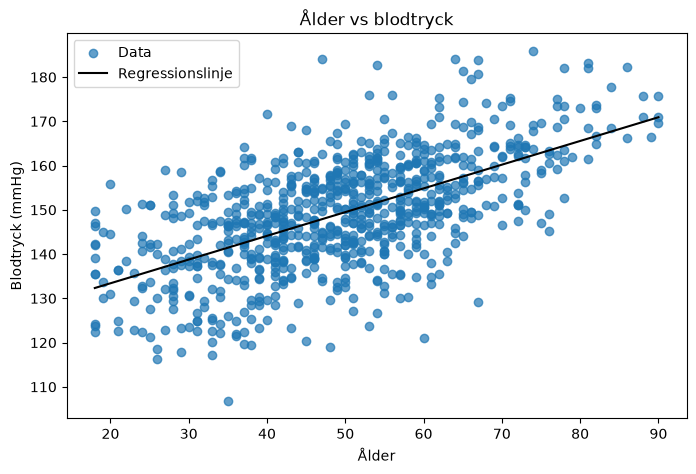

In [14]:
x_line_age = np.linspace(X_age.min(), X_age.max(), 100)
y_line_age = intercept_age + slope_age * x_line_age

fig, ax = plt.subplots()
viz.scatter(
    ax=ax,
    x=X_age, 
    y=y_age,
    alpha=0.7,
    title="Ålder vs blodtryck", 
    xlabel="Ålder", 
    ylabel="Blodtryck (mmHg)",
    grid=False,
    label="Data"
)
viz.plot_line(
    ax= ax,
    x= x_line_age,
    y= y_line_age,
    color="black",
    label="Regressionslinje"
)
plt.legend()
plt.show()

## Residualer 1
### Blodtryck - ålder

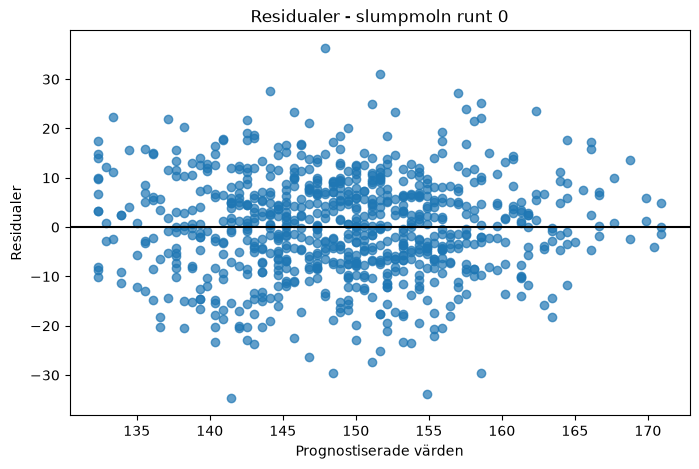

In [15]:
predictions_age, residuals_age = analyzer.predictions_and_residuals(X_age, y_age)

fig, ax = plt.subplots()
viz.scatter(
    ax= ax,
    x= predictions_age,
    y= residuals_age,
    alpha= 0.7,
    title= "Residualer - slumpmoln runt 0",
    xlabel= "Prognostiserade värden",
    ylabel= "Residualer",
    grid= False,
)
ax.axhline(0, color="black")
plt.show()

# Linjär regression 2
### Blodtryck - vikt

In [16]:
intercept_weight, slope_weight, r2_weight, X_weight, y_weight = analyzer.linear_regression("weight", "systolic_bp")

print(f"""
Intercept:  {intercept_weight:.2f}
Slope:      {slope_weight:.2f}
R^2:        {r2_weight:.3f}
""")


Intercept:  136.86
Slope:      0.17
R^2:        0.032



## Graf linjär regression 2
### Blodtryck - vikt

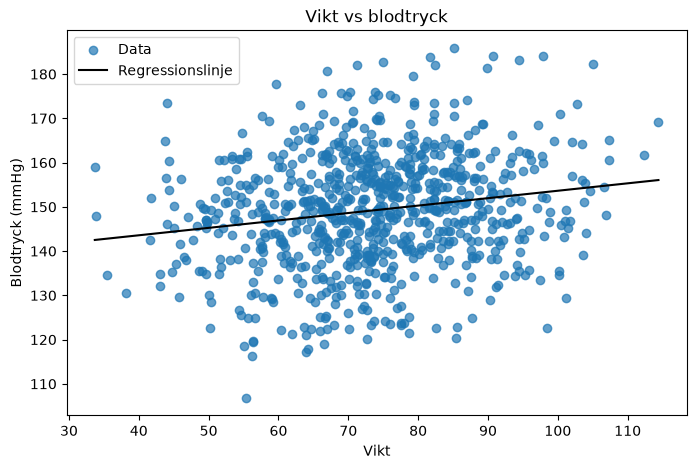

In [17]:
x_line_weight = np.linspace(X_weight.min(), X_weight.max(), 100)
y_line_weight = intercept_weight + slope_weight * x_line_weight

fig, ax = plt.subplots()
viz.scatter(
    ax=ax,
    x=X_weight, 
    y=y_weight,
    alpha=0.7,
    title="Vikt vs blodtryck", 
    xlabel="Vikt", 
    ylabel="Blodtryck (mmHg)",
    grid=False,
    label="Data"
)
viz.plot_line(
    ax= ax,
    x= x_line_weight,
    y= y_line_weight,
    color="black",
    label="Regressionslinje"
)
plt.legend()
plt.show()

## Residualer 2
### Blodtryck - vikt

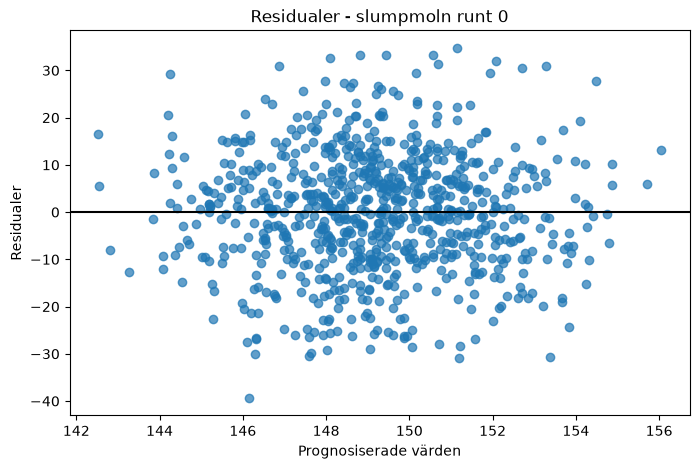

In [18]:
predictions_weight, residuals_weight = analyzer.predictions_and_residuals(X_weight, y_weight)

fig, ax = plt.subplots()
viz.scatter(
    ax= ax,
    x= predictions_weight,
    y= residuals_weight,
    alpha= 0.7,
    title= "Residualer - slumpmoln runt 0",
    xlabel= "Prognosiserade värden",
    ylabel= "Residualer",
    grid= False,
)
ax.axhline(0, color="black")
plt.show()

## Sammanfattning linjär regression

**Linjär regression 1 - ålder** 

**Skärning**: 122.68 

**Lutning**: 0.54 (0.54 mmHg ökning i snitt per ålder)

**($R^2$)**: 0.369 (ca. 36.9%)

**Linjär regression 2 - vikt** 

**Skärning**: 136.86 

**Lutning**: 0.17 (0.17 mmHg ökning i snitt per vikt)

**($R^2$)**: 0.032 (ca. 3.2%) 

Det vi ser i resultaten är skärningen, som anger skärningspunkten med y-axeln.
Lutningen som anger ett värde för hur det förväntade blodtrycket i genomsnitt ökar per vikt eller ålder. Sedan har vi **($R^2$)** som visar hur mycket i % där variationen kan förklars av ålder eller vikt, resterande % beror på andra faktorer.

Vi har valt att göra 2 linjära regressioner, de är **ålder** och **vikt** mot **blodtryck**. Detta för att göra en multipel regression på dem samtidigt och se vilka skillnader som finns mellan linjära regressioner och multipel regression.

Detta ger oss en förståelse om variablerna isolerat, vilken förändring per enhet (lutning), samt hur stor andel av variationen ($R^2$) som fångas.

Spridningsgrafen visar oss hur spridningen av datan är, i samband med den givna regressionslinjen som har räknats fram med hjälp av minsta kvadratmetoden.

Vi kontrollerar även träffsäkerheten, genom att analysera prediktioner och residualer, så kan vi se ifall det finns några systematiska fel eller spridning.


Modellerna är anpassade med `LinearRegression` i **`scikit-learn`** (som använder minsta kvadratmetoden på matrisen $X$ och målvektorn $y$; se dokumentationen för *scikit-learn `LinearRegression`*, attributen `intercept_`, `coef_` samt metoden `score` för $R^2$)

https://scikit-learn.org/stable/modules/linear_model.html

## Grafer och residualer

Graferna visar på att det finns en tydlig positiv trend, äldre eller högre vikt har i genomsnitt högre blodtryck. Punkterna har en ganska bred spridning kring linjen vilket stämmer mot vårt **($R^2$)**.

Residualer mot prognostiserade värden ser vi att punkterna ligger jämnt utspridda som ett slumpmoln kring 0 över hela spannet. Det tyder på att en linjär form är rimlig och att spridningen är jämn.



# Multipel regression

In [19]:
intercept_multi, slope_multi_age, slope_multi_weight, r2_multi, X_multi, y_multi = analyzer.multiple_regression(
    "age", "weight", "systolic_bp"
)

print(f"""
Intercept:  {intercept_multi:.2f}
Slope ålder:{slope_multi_age:.2f}
Slope vikt: {slope_multi_weight:.2f}
R^2:        {r2_multi:.3f}
""")


Intercept:  109.50
Slope ålder:0.54
Slope vikt: 0.18
R^2:        0.405



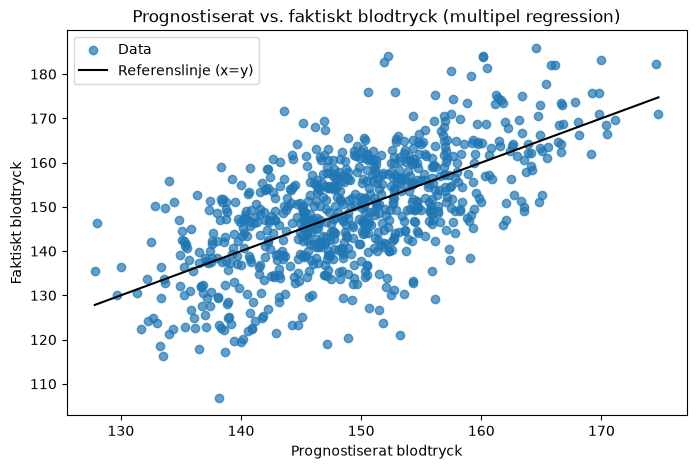

In [20]:
predictions_multi = analyzer.predictions_multi(X_multi)

ref_line = np.linspace(predictions_multi.min(), predictions_multi.max(), 100)

fig, ax = plt.subplots()
viz.scatter(
    ax=ax,
    x=predictions_multi, 
    y=y_multi,
    alpha=0.7,
    title="Prognostiserat vs. faktiskt blodtryck (multipel regression)", 
    xlabel="Prognostiserat blodtryck", 
    ylabel="Faktiskt blodtryck",
    grid=False,
    label="Data"
)
viz.plot_line(
    ax= ax,
    x= ref_line,
    y= ref_line,
    color="black",
    label="Referenslinje (x=y)"
)
plt.legend()
plt.show()

## Residuals
### Multipel regression

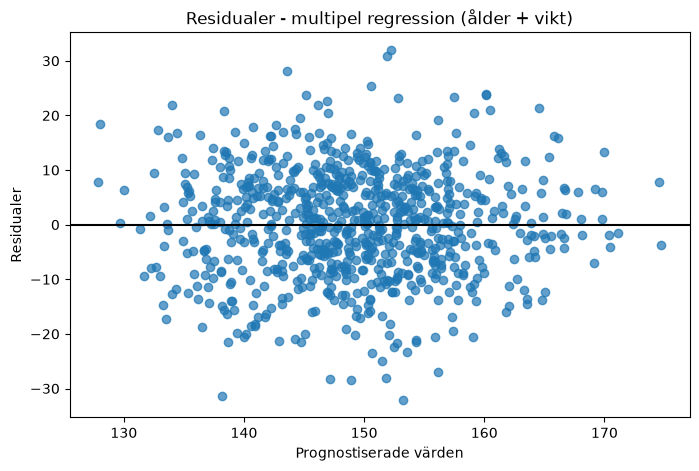

In [21]:
residuals_multi = y_multi - predictions_multi

fig, ax = plt.subplots()
viz.scatter(
    ax=ax,
    x=predictions_multi,
    y=residuals_multi,
    alpha=0.7,
    title="Residualer - multipel regression (ålder + vikt)",
    xlabel="Prognostiserade värden",
    ylabel="Residualer",
    grid=False,
)
ax.axhline(0, color="black")
plt.show()

| Modell | Skärning (Intercept) | Lutning ålder | Lutning vikt | $R^2$ |
| :--- | :--- | :--- | :--- | :--- |
| **Enkel – ålder** | 122.68 | 0.54 | – | 0.369 (36,9 %) |
| **Enkel – vikt** | 136.86 | – | 0.17 | 0.032 (3,2 %) |
| **Multipel – ålder & vikt** | 109.50 | 0.54 | 0.18 | 0.405 (40,5 %) |

Vi kan med dessa resultat se: 
- Ålder och vikt påverkar i stort sett oberoende av varandra.
- $R^2$ om man tar de linjära resultaten och adderar dem så får vi ca. utfallet av mutipla resultatet vilket säger oss att de separat bidrar med att förklara blodtrycket.


**Linjär regression vs multipel regression:** När vi sätter in både ålder och vikt i samma modell kan vi se att lutningarna ändras jämfört med de linjära modellerna och om den samlade modellen förklarar en större andel av variationen i blodtrycket. 